# **Libraries**

In [1]:
# Suppress the known TorchScript deprecation emitted by imported dependencies.
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"^`torch\.jit\.script` is deprecated\. Please switch to `torch\.compile` or `torch\.export`\.$",
    category=FutureWarning,
    module=r"^torch\.jit\._script$",
)

#Mathematics and ML
import torch

#Project package
from graphtools import graphon

#Autoreload module
"""
These magic lines allow to automatically reload any module.py file when there are some changes on it, without the needing of restart the kernel anytime a new change is applied to the module script
"""
%load_ext autoreload
%autoreload 2

# The graph is created directly on this device; downstream functions infer it.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# <h1 align="center">**W-random graph sampler** </h1>

Let $W \colon [0, 1]^2 \mapsto [0, 1]$ be a measurable function on the unit square called the _"graphon"_, then we can sample connections among nodes according to the law defined by $W$ as follows:

$$ \underbrace{z \overset{iid}{\sim} U[(0,1)]}_{\substack{\text{Latent coordinates representing} \\ \text{node's positions on the adjacency}}} \quad \longrightarrow \quad \underbrace{p_{ij} = W(z_i, z_j)}_{\substack{\text{Connection probability} \\ \text{between nodes }i \text{ and }j}} \quad \longrightarrow \quad \underbrace{a_{i, j} \overset{iid}{\sim} \operatorname{Ber}(p_{ij})}_{\text{Sample connection }(i,j)}$$

The graphon function then rules connections probabilities and can impose a specific structure on the adjacency matrix.

In [4]:
# Sample W-random graph
K = 5 #Number of states
n = 100 #Number of nodes

#Edges structure
structure = "random" #Graphon function
structure_kwargs = {}

#Position structure
positions = "bubbles" #Position generator

#Node states
state = "hard" #State generator
state_kwargs = {"K": K} #State generator parameters

graph = graphon.sample_graph(n, device = device, structure = structure, positions = positions, state = state, structure_kwargs = structure_kwargs, state_kwargs = state_kwargs)
print(f"Graph device: {graph.edge_index.device}")
graph

Graph device: cpu


Data(edge_index=[2, 4894], num_nodes=100, x=[100, 5], pos=[100, 2])

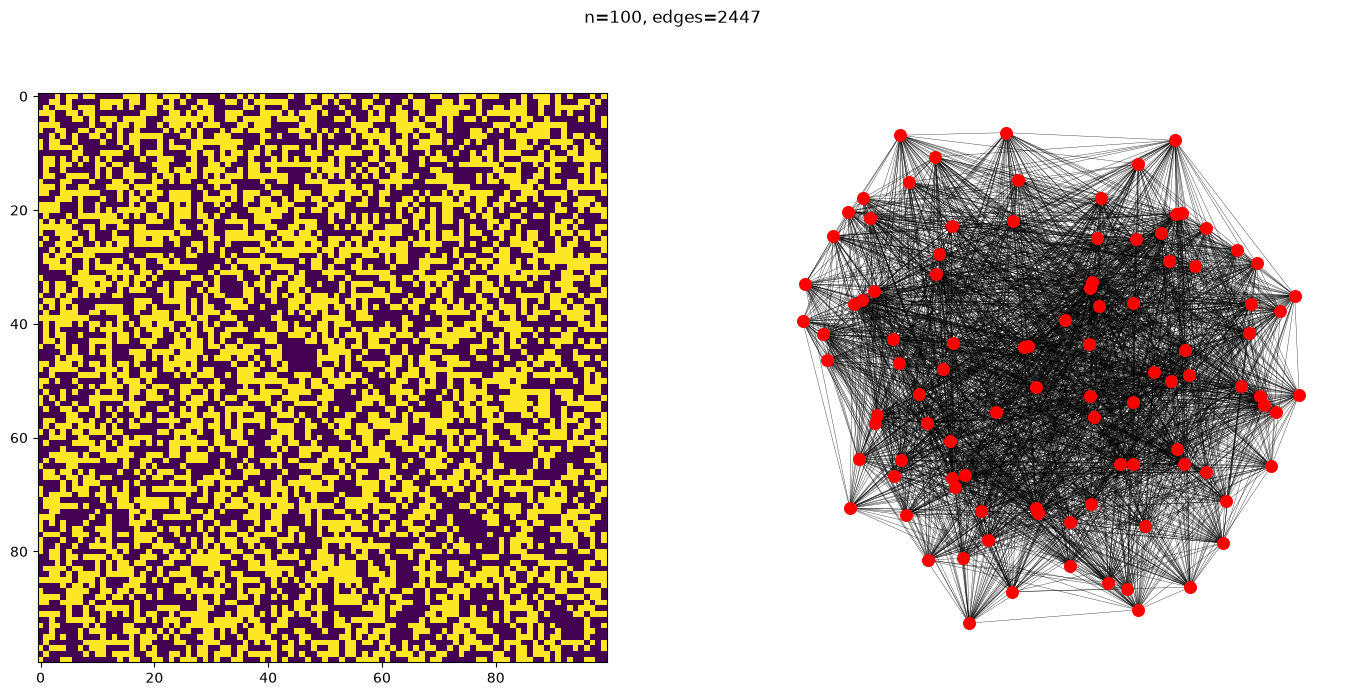

In [5]:
#Plot adjacency matrix and node positions
graphon.plot_graph(graph)